In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load California Housing Dataset

housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
# Select input and target variables

X = df[['MedInc']]
y = df['MedHouseVal']

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

print("\nInput Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features:
   MedInc
0  8.3252
1  8.3014
2  7.2574
3  5.6431
4  3.8462

Target Values:
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64

Input Shape: (20640, 1)
Target Shape: (20640,)


In [4]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)


Training Data Shape: (16512, 1)
Testing Data Shape: (4128, 1)
Training Target Shape: (16512,)
Testing Target Shape: (4128,)


In [5]:
# Create Linear Regression Model

model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model trained successfully!")

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Linear Regression Model trained successfully!
Coefficient: 0.4193384939381274
Intercept: 0.44459729169078677


In [6]:
# Predict housing prices

y_pred = model.predict(X_test)

# Compare actual and predicted prices
results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print("Housing Price Predictions:")
print(results.head(10))

Housing Price Predictions:
   Actual Price  Predicted Price
0       0.47700         1.149589
1       0.45800         1.506069
2       5.00001         1.903937
3       2.18600         2.850594
4       2.78000         2.006633
5       1.58700         2.421652
6       1.98200         2.576472
7       1.57500         1.992292
8       3.40000         2.458932
9       4.46600         3.846774


In [7]:
# Calculate evaluation metrics

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Squared Error (MSE):", mse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
Mean Squared Error (MSE): 0.7091157771765548
R2 Score: 0.45885918903846656


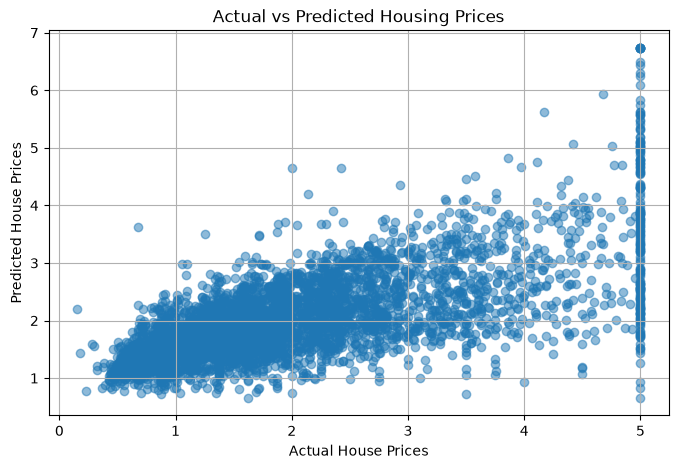

In [8]:
# Actual vs Predicted Price Visualization

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted Housing Prices")

plt.grid(True)
plt.show()

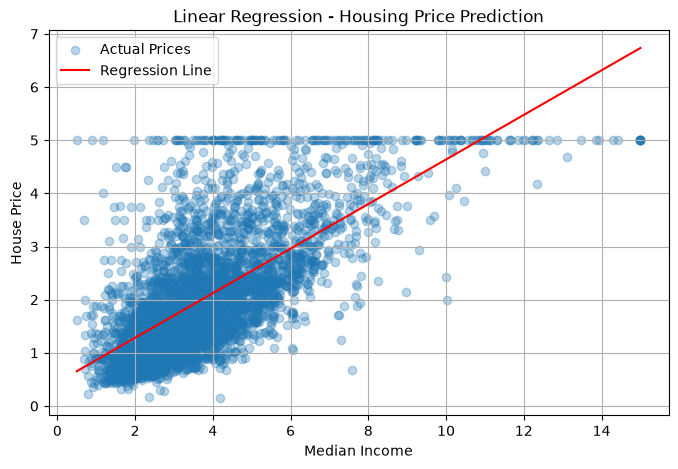

In [9]:
# Linear Regression Line Visualization

plt.figure(figsize=(8, 5))

plt.scatter(X_test['MedInc'], y_test,
            alpha=0.3, label="Actual Prices")

# Sort values to display a smooth regression line
sorted_indices = np.argsort(X_test['MedInc'].values)

plt.plot(
    X_test['MedInc'].values[sorted_indices],
    y_pred[sorted_indices],
    color='red',
    label="Regression Line"
)

plt.xlabel("Median Income")
plt.ylabel("House Price")
plt.title("Linear Regression - Housing Price Prediction")
plt.legend()
plt.grid(True)

plt.show()